# Total Perspective Vortex
## Treatment
---
Now that we've cleaned our data let's see what it looks like.

In [38]:
import mne
import numpy as np
import sklearn as skl
import pathlib as pth
import matplotlib.pyplot as plt
from mne.decoding import get_spatial_filter_from_estimator

In [39]:
PASSBAND_LOW    = 8
PASSBAND_HIGH   = 30

In [40]:
data_folder = pth.Path('eeg-motor-movementimagery-dataset-1.0.0/files')

# Change with a iterdir loop or a data selector.
s001 = data_folder / 'S001'

%matplotlib qt
s001r03 = s001 / 'S001R03.edf'
raw = mne.io.read_raw_edf(s001r03)
data = raw.load_data()
data.plot()

data_cpy = data.copy()
data_cpy.filter(PASSBAND_LOW, PASSBAND_HIGH, verbose=False)

data_cpy.plot()

plt.show()

Extracting EDF parameters from eeg-motor-movementimagery-dataset-1.0.0/files/S001/S001R03.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Channels marked as bad:
none
Channels marked as bad:
none


With theses plots, we can see that the signal have **less noise**, after the filter.

Now, we can try to pass the signal through a **Spatial Filter** and check what the values look like.
Thanks to [this papper](https://doc.ml.tu-berlin.de/bbci/publications/BlaTomLemKawMue08.pdf), we have this **comparison** of graphs that illustrate the filtering of different **spatial filter**.

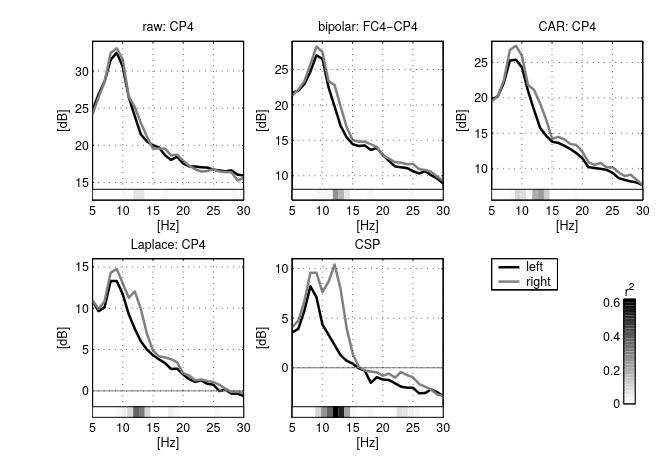

We can see that there's two graphs that really differentiate between **right** and **left**: CSP and Laplace.
This information is validated by this, previously referenced, [github repo](https://github.com/RezaSaadatyar/Motor-imagery-based-EEG-signal-processing), which use **both of them**.

Since the most commonly used is the **CSP**, for **Common Spatial Pattern**, we'll start by this.

Used Annotations descriptions: [np.str_('T0'), np.str_('T1'), np.str_('T2')]
Computing rank from data with rank=None
    Using tolerance 0.00047 (2.2e-16 eps * 64 dim * 3.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=2 covariance using EMPIRICAL
Done.
Estimating class=3 covariance using EMPIRICAL
Done.


/tmp/ipykernel_3051798/1786306070.py:27: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  fig_pattern = mne.decoding.get_spatial_filter_from_estimator(csp, epochs.info).plot_patterns(ch_type='eeg', extrapolate='local')


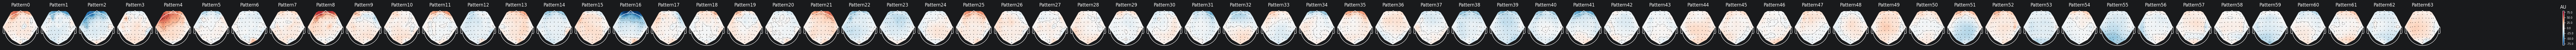

In [44]:
ch_names = raw.ch_names
ch_names = {name: name.rstrip('.') for name in ch_names}
sfreq = 160
montage = mne.channels.make_standard_montage('standard_1005')
raw.rename_channels(lambda name: name.rstrip('.'))
raw.set_montage(montage, on_missing='ignore', match_case=False)

events, events_id = mne.events_from_annotations(raw)

# CSP doesn't really work for multi class, that's why we'll only use the two most important part (T1 and T2)

events_id = {
    'T1': events_id['T1'],
    'T2': events_id['T2'],
}

epochs = mne.Epochs(raw, events, events_id, tmin=0.5, tmax=3, baseline=None, preload=True, verbose=False)

X_extract = epochs.get_data(copy=True)
y_extract = epochs.events[:, -1]

csp = mne.decoding.CSP(n_components=4, reg=None, log=True, norm_trace=False)

csp.fit(X_extract, y_extract)

%matplotlib inline
fig_pattern = mne.decoding.get_spatial_filter_from_estimator(csp, epochs.info).plot_patterns(ch_type='eeg', extrapolate='local')
plt.show()

NOTE: plot_filters() is a legacy function. New code should use get_spatial_filter_from_estimator(clf, info=info).plot_filters().


/tmp/ipykernel_3051798/2379026169.py:2: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  fig_filters = csp.plot_filters(epochs.info, ch_type='eeg')


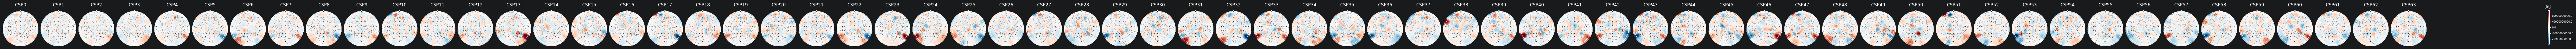

In [45]:
%matplotlib inline
fig_filters = csp.plot_filters(epochs.info, ch_type='eeg')
plt.show()

Those plots show us the different **patterns** found by **CSP** for each of the 64 electrodes.

There are electrodes that carry more information than the others.

And by printing the shape of the **CSP transformed** data set...

In [43]:
print(f"Extracted data shape: {X_extract.shape}")

print(f"CSP Transformed data shape: {csp.transform(X_extract).shape}")

Extracted data shape: (15, 64, 401)
CSP Transformed data shape: (15, 4)


We can see that, compared to the **extracted data**, we have a lot less information !

It's with those newly transformed data that we'll train ou model !